# Counterfeit Medicine Packaging Classification
## Deep Learning: AlexNet & GoogLeNet Implementation with Overfitting Reduction Techniques

### Step 1: Import Libraries and Download Dataset
We import the required libraries (TensorFlow for the deep learning pipeline, Kagglehub to retrieve the dataset, Matplotlib/Seaborn for diagnostics, and Gradio for deployment).

In [ ]:
!pip install -q gradio kagglehub scikit-learn seaborn

import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import gradio as gr

from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score
)

# Set random seeds for reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Download dataset
dataset_path = kagglehub.dataset_download(
    "surajkumarjha1/fake-vs-real-medicine-datasets-images"
)

# Locate root folder containing train, val, and test splits
dataset_root = None
for root, dirs, _ in os.walk(dataset_path):
    if {"train", "val", "test"}.issubset({d.lower() for d in dirs}):
        dataset_root = root
        break

if not dataset_root:
    raise FileNotFoundError("Could not locate training, validation, and test split folders.")

train_dir = os.path.join(dataset_root, "train")
val_dir = os.path.join(dataset_root, "val")
test_dir = os.path.join(dataset_root, "test")

print(f"Dataset located at: {dataset_root}")
print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices('GPU'))

100%|██████████| 267M/267M [00:03<00:00, 85.7MB/s]

Extracting files...


Dataset located at: /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset
TensorFlow Version: 2.21.0
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Step 2: Load Data into Batches
Using TensorFlow's `image_dataset_from_directory`, we load images resized to $128 \times 128$ in batches of 32. Label mode is set to `'binary'` (Alphabetical mapping: `0` = Fake, `1` = Real).

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Optimize I/O throughput with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)


Found 661 files belonging to 2 classes.
Found 449 files belonging to 2 classes.


### Diagnostic 1: Dataset Split & Class Imbalance Distribution
Quantify the number of 'Fake' (0) and 'Real' (1) images in each split to evaluate class distribution.

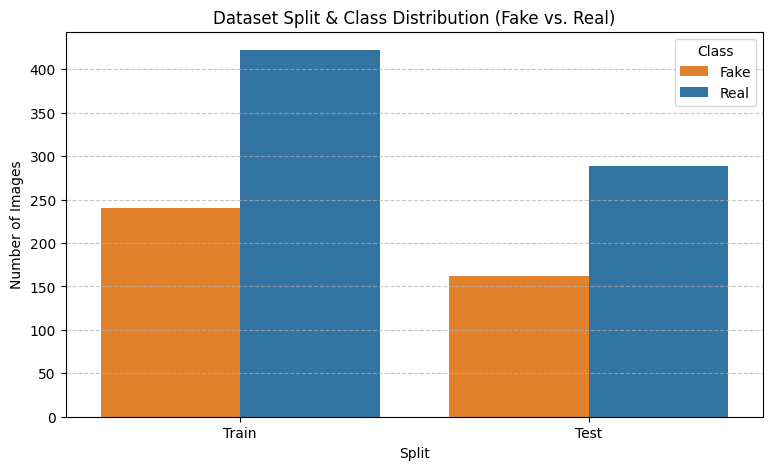

Training Imbalance Ratio (Real / Fake): 1.76 : 1


In [ ]:
def count_classes(directory):
    fake_count = len(os.listdir(os.path.join(directory, 'Fake')))
    real_count = len(os.listdir(os.path.join(directory, 'Real')))
    return fake_count, real_count

train_fake, train_real = count_classes(train_dir)
test_fake, test_real = count_classes(test_dir)

data = {
    'Split': ['Train', 'Train', 'Test', 'Test'],
    'Class': ['Fake', 'Real', 'Fake', 'Real'],
    'Count': [train_fake, train_real, test_fake, test_real]
}
df_dist = pd.DataFrame(data)

plt.figure(figsize=(9, 5))
sns.barplot(x='Split', y='Count', hue='Class', data=df_dist, palette=['#ff7f0e', '#1f77b4'])
plt.title('Dataset Split & Class Distribution (Fake vs. Real)')
plt.ylabel('Number of Images')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(f"Training Imbalance Ratio (Real / Fake): {train_real / train_fake:.2f} : 1")


### Diagnostic 2: Exploratory Medicine Packaging Sample Gallery
Inspect a raw batch of unaugmented images to verify label alignments and visual packaging characteristics.

Found 661 files belonging to 2 classes.


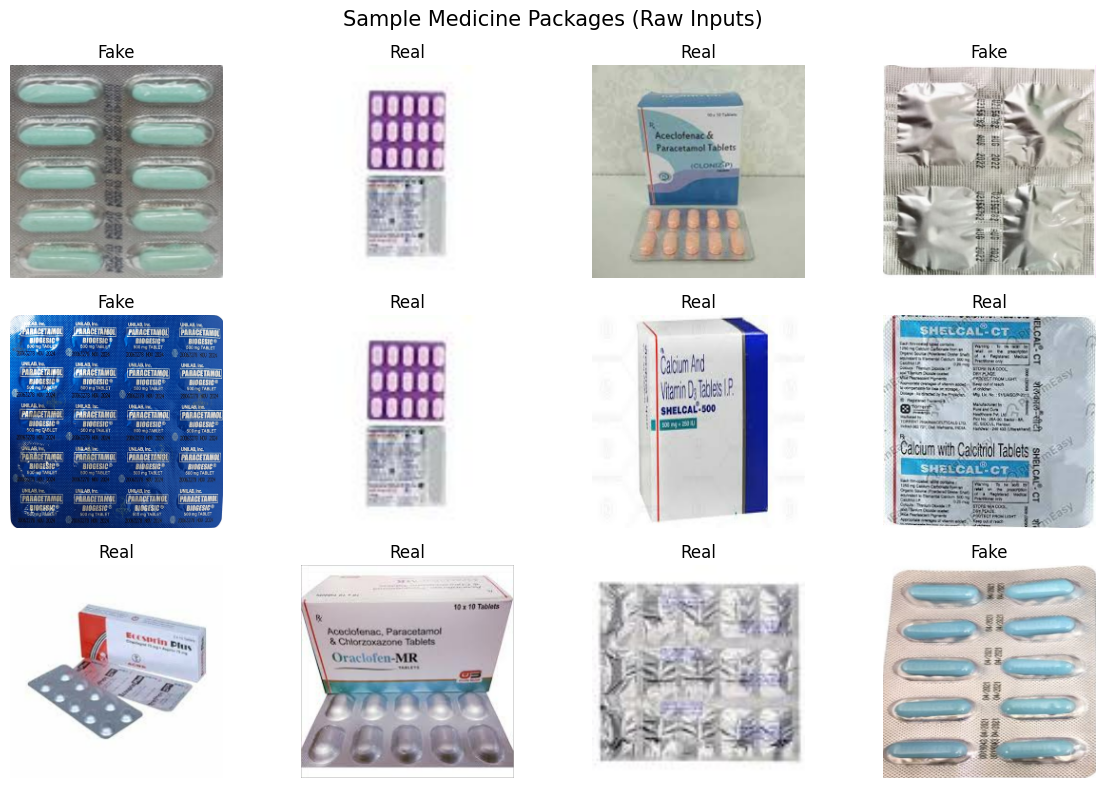

In [ ]:
class_names = ['Fake', 'Real']

# Sample a batch of unaugmented training images
raw_train = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=12,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

for images, labels in raw_train.take(1):
    plt.figure(figsize=(12, 8))
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
    plt.suptitle("Sample Medicine Packages (Raw Inputs)", fontsize=15)
    plt.tight_layout()
    plt.show()

### Diagnostic 3: In-Graph Data Augmentation Pipeline & Preview
Data augmentation expands the training manifold to reduce overfitting. We constrain rotations, zoom, and lighting adjustments so micro-text and blister-pack textures remain intact.

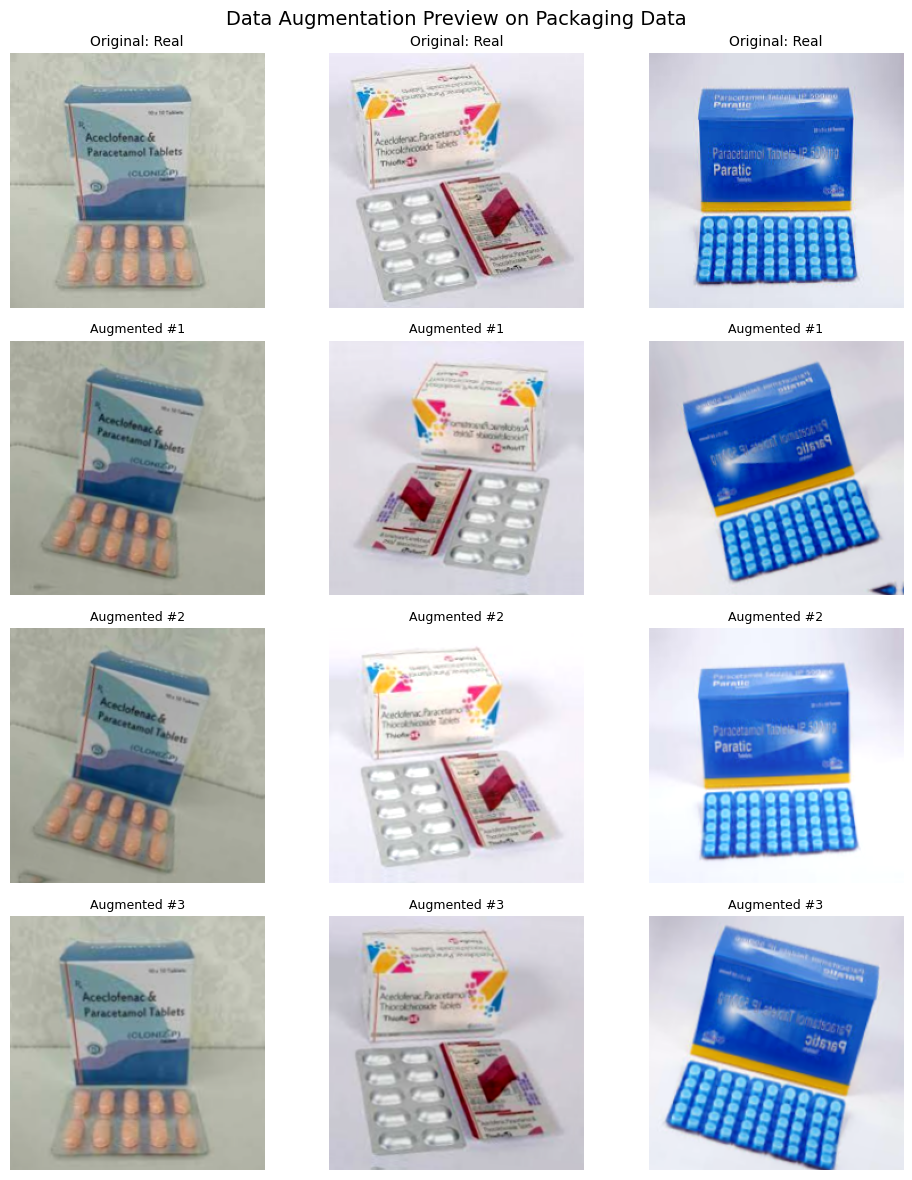

In [ ]:
# Define in-graph data augmentation block
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),     # +/- 18 degrees tilt
    layers.RandomZoom(0.10),         # +/- 10% distance scaling
    layers.RandomBrightness(0.10, value_range=(0.0, 255.0)),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# Preview augmentation on 3 sample images
for images, labels in raw_train.take(1):
    sample_images = images[:3]
    sample_labels = labels[:3]

fig, axes = plt.subplots(4, 3, figsize=(10, 12))
for col in range(3):
    orig = sample_images[col].numpy().astype("uint8")
    lbl_name = class_names[int(sample_labels[col][0])]
    axes[0, col].imshow(orig)
    axes[0, col].set_title(f"Original: {lbl_name}", fontsize=10)
    axes[0, col].axis("off")
    for row in range(1, 4):
        aug = data_augmentation(tf.expand_dims(sample_images[col], 0), training=True)
        axes[row, col].imshow(tf.squeeze(aug).numpy().astype("uint8"))
        axes[row, col].set_title(f"Augmented #{row}", fontsize=9)
        axes[row, col].axis("off")

plt.suptitle("Data Augmentation Preview on Packaging Data", fontsize=14)
plt.tight_layout()
plt.show()

## Assignment 1 - Part 1: AlexNet Architecture & Overfitting Analysis
To satisfy the academic requirement of demonstrating **overfitting reduction techniques**, we perform a controlled comparative experiment:
1. **Baseline AlexNet (Unregularized)**: Trained without data augmentation, without Dropout, and without weight decay. It rapidly memorizes the small dataset (~661 training images), causing validation loss to diverge.
2. **Regularized AlexNet**: Includes in-graph data augmentation, Dropout (0.5), $L_2$ weight decay, and EarlyStopping to suppress memorization and maintain generalization.

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomBrightness(0.10, value_range=(0.0, 255.0)),
    layers.RandomContrast(0.10)
], name="data_augmentation")

def build_alexnet(input_shape=(224, 224, 3), regularized=True):
    inputs = layers.Input(shape=input_shape)

    if regularized:
        x = data_augmentation(inputs)
        x = layers.Rescaling(1.0 / 255)(x)
        l2_reg = regularizers.l2(1e-4) # Restored L2
    else:
        x = layers.Rescaling(1.0 / 255)(inputs)
        l2_reg = None

    # Conv Block 1
    x = layers.Conv2D(64, (7, 7), strides=2, padding='same', use_bias=False, kernel_regularizer=l2_reg)(x)
    if regularized: x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, padding='same')(x)

    # Conv Block 2
    x = layers.Conv2D(128, (5, 5), padding='same', use_bias=False, kernel_regularizer=l2_reg)(x)
    if regularized: x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, padding='same')(x)

    # Conv Blocks 3, 4, 5
    x = layers.Conv2D(256, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2_reg)(x)
    if regularized: x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(256, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2_reg)(x)
    if regularized: x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2_reg)(x)
    if regularized: x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, padding='same')(x)

    # Classifier Dense Head
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=l2_reg)(x)
    if regularized:
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(0.5)(x)

    x = layers.Dense(128, activation='relu', kernel_regularizer=l2_reg)(x)
    if regularized:
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="AlexNet_Regularized" if regularized else "AlexNet_Baseline")
    return model

# Build both models
alexnet_baseline = build_alexnet(regularized=False)
alexnet_regularized = build_alexnet(regularized=True)

# Use CosineDecay with Warmup
steps_per_epoch = len(train_ds)
lr_schedule_alx = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=15 * steps_per_epoch,
    alpha=0.01,
    warmup_target=1e-3,
    warmup_steps=2 * steps_per_epoch
)

# Implement Gradient Clipping to cap explosive updates
alexnet_baseline.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0), loss='binary_crossentropy', metrics=['accuracy'])
alexnet_regularized.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule_alx, clipnorm=1.0), loss='binary_crossentropy', metrics=['accuracy'])


### Step 4: Model Training
We train the model using our training and validation datasets over 10 epochs.

In [ ]:
EPOCHS = 15

# Calculate balanced class weights
total = train_fake + train_real
weight_for_0 = (1 / train_fake) * (total / 2.0)
weight_for_1 = (1 / train_real) * (total / 2.0)
class_weight = {0: weight_for_0, 1: weight_for_1}

print("--- Training Baseline AlexNet (Unregularized) ---")
history_baseline = alexnet_baseline.fit(
    train_ds,
    epochs=EPOCHS,
    class_weight=class_weight
)

print("\n--- Training Regularized AlexNet (Data Aug, Dropout, L2) ---")
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='loss', patience=4, restore_best_weights=True
)

history_regularized = alexnet_regularized.fit(
    train_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    class_weight=class_weight
)

# For downstream compatibility, assign the regularized model to 'model'
model = alexnet_regularized
history = history_regularized


--- Training Baseline AlexNet (Unregularized) ---
Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.5446 - loss: 0.8889
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6051 - loss: 0.6850
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7020 - loss: 0.6533
Epoch 4/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6566 - loss: 0.7529
Epoch 5/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6823 - loss: 0.6357
Epoch 6/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7307 - loss: 0.5687
Epoch 7/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6581 - loss: 0.7384
Epoch 8/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7700 - loss: 0.5221
Epoch 9/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7852 - loss: 0.4653
Epoch 10/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8079 - loss: 0.6414
Epoch 11/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8321 - loss: 0.4764
Epoch 12/15
42/42 ━━━━

### Diagnostic 4: Loss & Accuracy Convergence Curves
Let's visualize the training and validation metric history across epochs to identify whether our network converged or started to overfit.

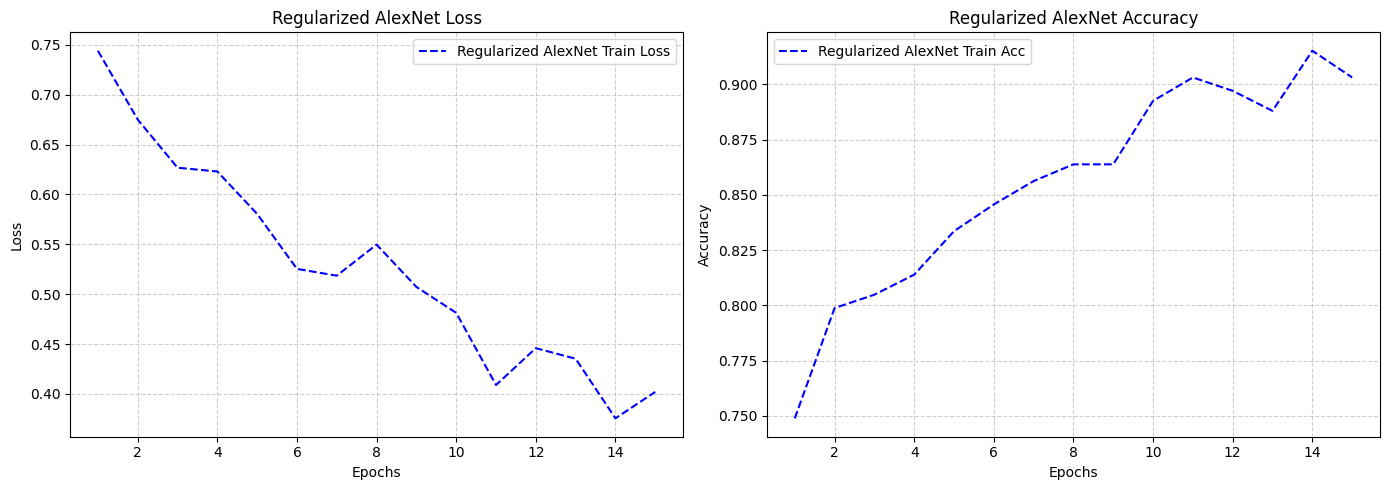

In [ ]:
def plot_history(hist, model_name):
    epochs = range(1, len(hist.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    t_l = hist.history['loss']
    t_a = hist.history['accuracy']

    # Loss Plot
    axes[0].plot(epochs, t_l, color='blue', linestyle='--', label=f'{model_name} Train Loss')
    if 'val_loss' in hist.history:
        axes[0].plot(epochs, hist.history['val_loss'], color='orange', linestyle='-', lw=2, label=f'{model_name} Val Loss')
    axes[0].set_title(f'{model_name} Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Accuracy Plot
    axes[1].plot(epochs, t_a, color='blue', linestyle='--', label=f'{model_name} Train Acc')
    if 'val_accuracy' in hist.history:
        axes[1].plot(epochs, hist.history['val_accuracy'], color='orange', linestyle='-', lw=2, label=f'{model_name} Val Acc')
    axes[1].set_title(f'{model_name} Accuracy')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_history(history_regularized, "Regularized AlexNet")


### Step 5: Evaluate on Unseen Test Data
Finally, we run a validation check on our holdout test set to ensure the trained model generalises well to unseen real-world medicine package images.

In [ ]:
print("--- Evaluating Baseline AlexNet (Unregularized) ---")
base_loss, base_acc = alexnet_baseline.evaluate(test_ds)
print(f"Baseline Test Accuracy: {base_acc * 100:.2f}%\n")

print("--- Evaluating Regularized AlexNet ---")
reg_loss, reg_acc = alexnet_regularized.evaluate(test_ds)
print(f"Regularized Test Accuracy: {reg_acc * 100:.2f}%")

# Ensure the regularized model is set as the main model for subsequent diagnostics
model = alexnet_regularized

--- Evaluating Baseline AlexNet (Unregularized) ---
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9443 - loss: 0.2022
Baseline Test Accuracy: 94.43%

--- Evaluating Regularized AlexNet ---
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9310 - loss: 0.3214
Regularized Test Accuracy: 93.10%


## Assignment 1 - Part 2: GoogLeNet Architecture (Inception Modules)
We now implement a simplified GoogLeNet utilizing Inception blocks to capture multi-scale spatial features of the medicine packaging.

In [ ]:
def conv2d_bn(x, filters, kernel_size, strides=1, padding='same'):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding=padding, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def inception_module(x, filters):
    f1, f3_in, f3, f5_in, f5, pool_proj = filters

    # 1x1 conv
    conv1 = conv2d_bn(x, f1, (1, 1))

    # 3x3 conv
    conv3 = conv2d_bn(x, f3_in, (1, 1))
    conv3 = conv2d_bn(conv3, f3, (3, 3))

    # 5x5 conv
    conv5 = conv2d_bn(x, f5_in, (1, 1))
    conv5 = conv2d_bn(conv5, f5, (5, 5))

    # 3x3 max pooling
    pool = layers.MaxPooling2D((3, 3), strides=(1, 1), padding='same')(x)
    pool = conv2d_bn(pool, pool_proj, (1, 1))

    # Concatenate filters
    return layers.concatenate([conv1, conv3, conv5, pool], axis=-1)

def build_googlenet(input_shape=(224, 224, 3)):
    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    # Adjusted strides and added BatchNormalization for smoothness
    x = conv2d_bn(x, 64, (7, 7), strides=1)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    x = conv2d_bn(x, 64, (1, 1))
    x = conv2d_bn(x, 192, (3, 3))
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    # Two Inception Blocks
    x = inception_module(x, [64, 96, 128, 16, 32, 32])
    x = inception_module(x, [128, 128, 192, 32, 96, 64])
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    x = layers.GlobalAveragePooling2D()(x)

    # Moderate dropout for stability
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(1, activation='sigmoid')(x)

    return models.Model(inputs, outputs, name="GoogLeNet_Smooth")

googlenet_model = build_googlenet()

# Use CosineDecay with linear warmup for smoothly transitioning LR
steps_per_epoch = len(train_ds)
lr_schedule_gn = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=15 * steps_per_epoch,
    alpha=0.01,
    warmup_target=1e-3,
    warmup_steps=2 * steps_per_epoch
)

# Compile with gradient clipping
googlenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule_gn, clipnorm=1.0),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
googlenet_model.summary()


Model: "GoogLeNet_Smooth"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 224, 224,  │      9,408 │ rescaling_2[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        256 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 112, 112,  │          0 │ activation_10[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 112, 112,  │      4,096 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 112, 112,  │    110,592 │ activation_11[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        768 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 56, 56,    │          0 │ activation_12[0]… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 56, 56,    │     18,432 │ max_pooling2d_7[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 56, 56,    │      3,072 │ max_pooling2d_7[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        384 │ conv2d_14[0][0] 

 Total params: 681,313 (2.60 MB)

 Trainable params: 678,657 (2.59 MB)

 Non-trainable params: 2,656 (10.38 KB)

In [ ]:
print("--- Training GoogLeNet ---")
early_stopping_gn = tf.keras.callbacks.EarlyStopping(
    monitor='loss', patience=4, restore_best_weights=True
)

# Removed ReduceLROnPlateau since CosineDecay is integrated into optimizer
googlenet_history = googlenet_model.fit(
    train_ds,
    epochs=15,
    callbacks=[early_stopping_gn],
    class_weight=class_weight
)

# Evaluate GoogLeNet
print("\n--- Evaluating GoogLeNet ---")
gn_loss, gn_acc = googlenet_model.evaluate(test_ds)
print(f"GoogLeNet Test Accuracy: {gn_acc * 100:.2f}%")

# Set GoogLeNet as the primary model for downstream evaluations and diagnostics
model = googlenet_model
history = googlenet_history


--- Training GoogLeNet ---
Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.7821 - loss: 0.4995
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8366 - loss: 0.4194
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8366 - loss: 0.3890
Epoch 4/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8517 - loss: 0.3322
Epoch 5/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8548 - loss: 0.3226
Epoch 6/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8623 - loss: 0.3433
Epoch 7/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8669 - loss: 0.3306
Epoch 8/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8759 - loss: 0.2922
Epoch 9/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8790 - loss: 0.2706
Epoch 10/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8880 - loss: 0.2585
Epoch 11/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8986 - loss: 0.2539
Epoch 12/15
42/42 ━━━━━━━━━━━━━━━━━━

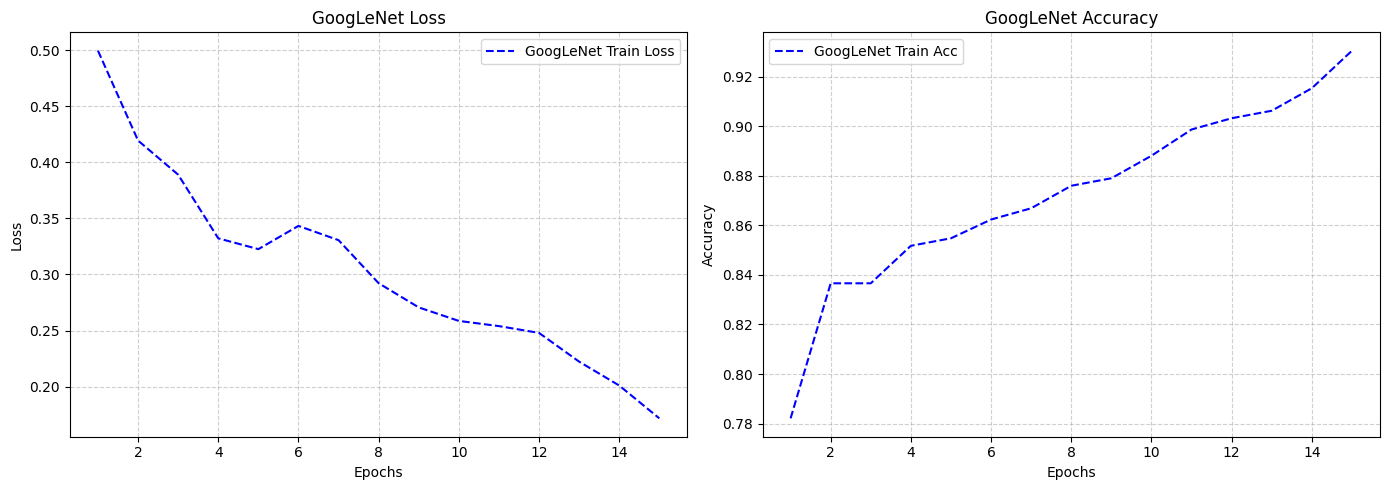

In [ ]:
plot_history(googlenet_history, "GoogLeNet")

### Diagnostic 5: Binary Confusion Matrix Heatmap
To quantify specific risk profiles, let us construct a Confusion Matrix on the holdout test set to look for False Positives (counterfeit drugs classified as Genuine/Real) vs. False Negatives.

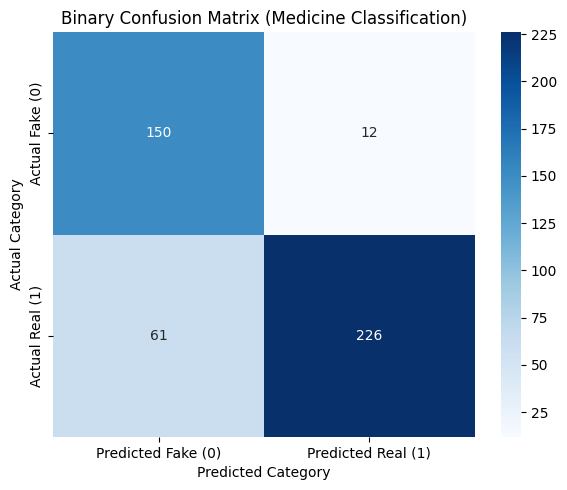

In [ ]:
from sklearn.metrics import confusion_matrix

# Extract labels and predict probabilities on the entire test dataset
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy().flatten())
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred_labels = (y_pred_probs >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Fake (0)', 'Predicted Real (1)'],
            yticklabels=['Actual Fake (0)', 'Actual Real (1)'])
plt.title('Binary Confusion Matrix (Medicine Classification)')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()

### Diagnostic 6: Discrimination Analysis: ROC and Precision-Recall Curves
Let's evaluate the sensitivity-specificity trade-off and calculate the area under both the ROC and Precision-Recall curves.

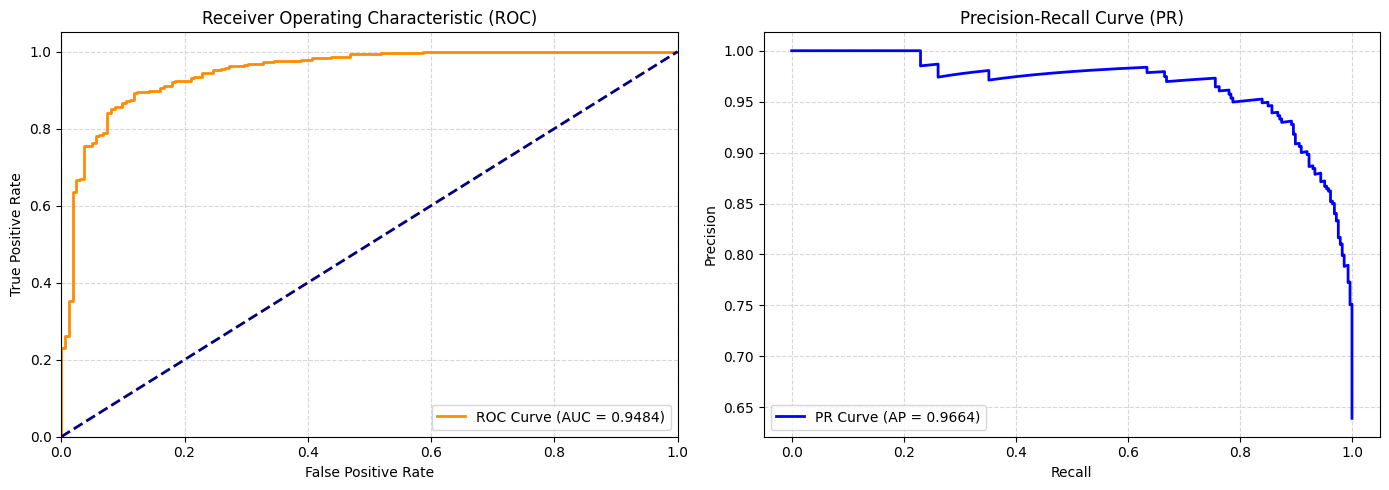

In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_true, y_pred_probs)
pr_auc = average_precision_score(y_true, y_pred_probs)

plt.figure(figsize=(14, 5))

# Subplot 1: ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='blue', lw=2, label=f'PR Curve (AP = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (PR)')
plt.legend(loc="lower left")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Diagnostic 7: Decision Threshold Optimization Plot
Since allowing fake drugs to slip through as genuine presents a severe risk, we evaluate Precision, Recall, and F1-score across all decision thresholds from 0 to 1 to find the safest threshold point.

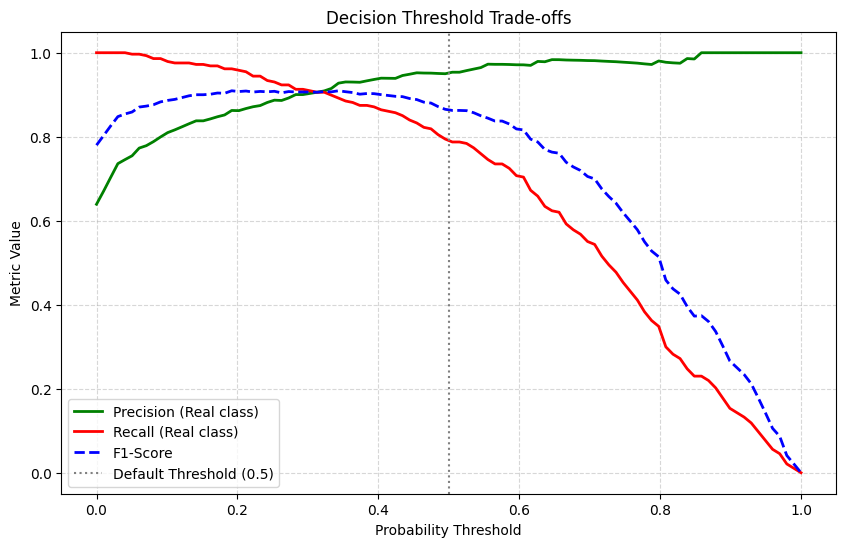

In [ ]:
thresholds = np.linspace(0, 1, 100)
precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    preds_t = (y_pred_probs >= t).astype(int)
    # Compute True Positives, False Positives, False Negatives manually or via sklearn
    tp = np.sum((y_true == 1) & (preds_t == 1))
    fp = np.sum((y_true == 0) & (preds_t == 1))
    fn = np.sum((y_true == 1) & (preds_t == 0))

    p = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

    precisions.append(p)
    recalls.append(r)
    f1_scores.append(f1)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision (Real class)', color='g', lw=2)
plt.plot(thresholds, recalls, label='Recall (Real class)', color='r', lw=2)
plt.plot(thresholds, f1_scores, label='F1-Score', color='b', linestyle='--', lw=2)
plt.axvline(x=0.5, color='gray', linestyle=':', label='Default Threshold (0.5)')
plt.title('Decision Threshold Trade-offs')
plt.xlabel('Probability Threshold')
plt.ylabel('Metric Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Diagnostic 8: Qualitative Prediction Gallery with Confidence Scores
Finally, we plot sample test images side by side with the model predictions. Correct classifications are marked in Green, while incorrect ones are marked in Red.

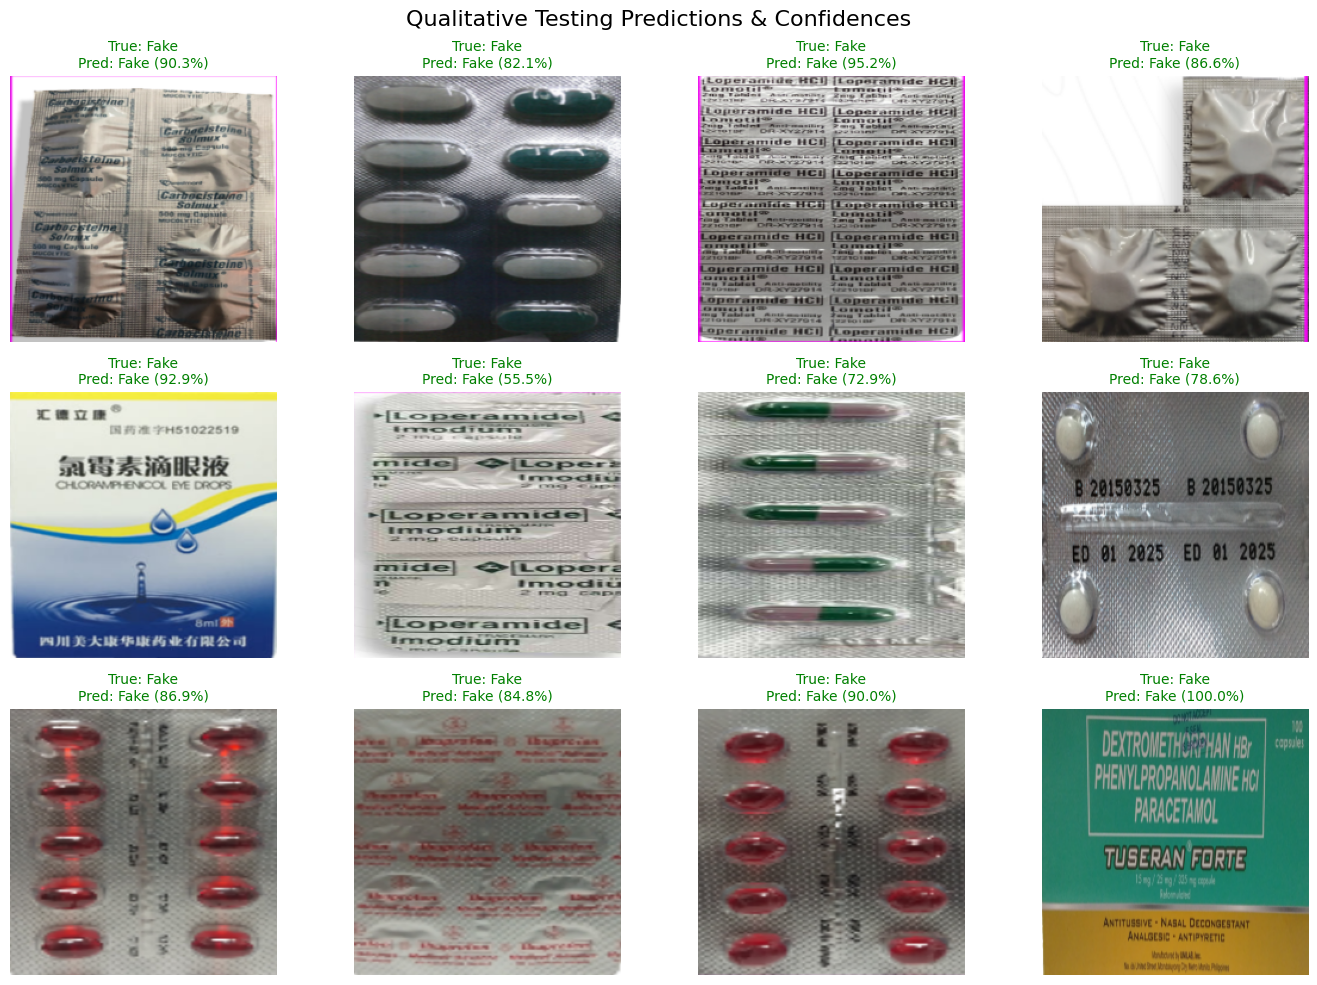

In [ ]:
# Fetch one batch of test images
for test_images, test_labels in test_ds.take(1):
    test_preds = model.predict(test_images, verbose=0)

    plt.figure(figsize=(14, 10))
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(test_images[i].numpy().astype("uint8"))

        true_label = int(test_labels[i][0])
        pred_prob = test_preds[i][0]
        pred_label = int(pred_prob >= 0.5)

        color = 'green' if true_label == pred_label else 'red'
        title_text = f"True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({pred_prob*100 if pred_label==1 else (1-pred_prob)*100:.1f}%)"

        plt.title(title_text, color=color, fontsize=10)
        plt.axis("off")
    plt.suptitle("Qualitative Testing Predictions & Confidences", fontsize=16)
    plt.tight_layout()
    plt.show()

### Step 6: Target Class Inversion (Treating 'Fake' as the Positive Class)
By default, alphabetical ordering makes `Fake = 0` and `Real = 1`. For pharmaceutical safety and counterfeit surveillance, we want to treat `Fake` as our positive class (1) to measure recall and precision against counterfeits. Let's extract the ground-truth targets and calculate the inverted probabilities where $P(\text{Fake}) = 1.0 - P(\text{Real})$.

In [ ]:
from sklearn.metrics import (
    precision_recall_curve, roc_curve, auc,
    average_precision_score, confusion_matrix, classification_report
)

# 1. Extract ground truth labels and predicted probabilities from the test set
y_true_real = np.concatenate([y.numpy() for _, y in test_ds], axis=0).ravel()
y_pred_prob_real = model.predict(test_ds).ravel()

# 2. Invert both labels and probabilities to make 'Fake' the positive class (1)
y_true_fake = (y_true_real == 0).astype(int)
y_pred_prob_fake = 1.0 - y_pred_prob_real

print("Labels inverted successfully. 'Fake' is now positive (1) and 'Real' is negative (0).")

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Labels inverted successfully. 'Fake' is now positive (1) and 'Real' is negative (0).


### Step 7: Corrected Decision Threshold Optimization Curve
Now, we evaluate our model performance across a spectrum of classification thresholds. This sweep helps find the optimal threshold ($\tau^*$) maximizing the $F_1$-score on counterfeits, allowing us to bias our threshold for consumer safety (high recall on `Fake` samples).

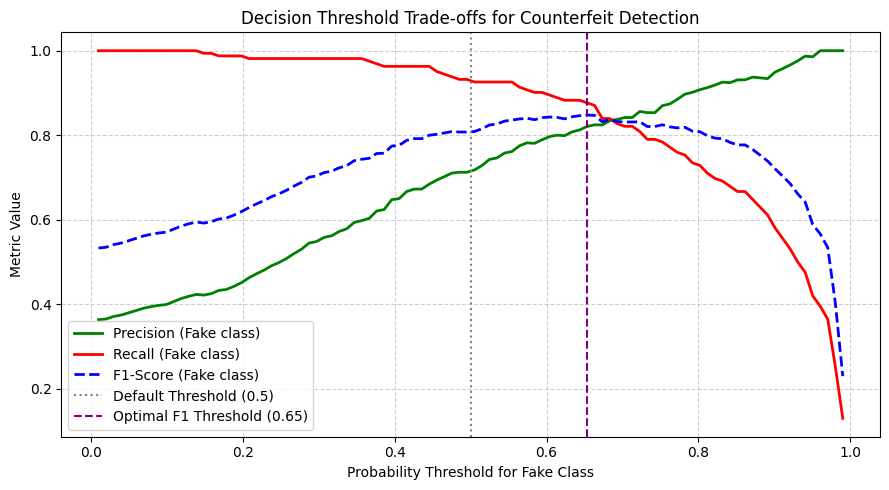

Optimal Threshold for Fake Detection: 0.653
Metrics at Optimal Threshold -> Precision: 0.821, Recall: 0.877, F1: 0.848


In [ ]:
# Evaluate metrics across threshold range
thresholds = np.linspace(0.01, 0.99, 100)
precisions, recalls, f1_scores = [], [], []

for t in thresholds:
    y_pred_fake = (y_pred_prob_fake >= t).astype(int)

    # Calculate True Positives, False Positives, False Negatives for 'Fake'
    tp = np.sum((y_pred_fake == 1) & (y_true_fake == 1))
    fp = np.sum((y_pred_fake == 1) & (y_true_fake == 0))
    fn = np.sum((y_pred_fake == 0) & (y_true_fake == 1))

    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0

    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)

# Identify threshold maximizing F1-score for Fake detection
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx]

# Plot Corrected Threshold Curve
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, 'g-', label='Precision (Fake class)', linewidth=2)
plt.plot(thresholds, recalls, 'r-', label='Recall (Fake class)', linewidth=2)
plt.plot(thresholds, f1_scores, 'b--', label='F1-Score (Fake class)', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', label='Default Threshold (0.5)')
plt.axvline(x=optimal_threshold, color='purple', linestyle='--',
            label=f'Optimal F1 Threshold ({optimal_threshold:.2f})')

plt.title('Decision Threshold Trade-offs for Counterfeit Detection', fontsize=12)
plt.xlabel('Probability Threshold for Fake Class', fontsize=10)
plt.ylabel('Metric Value', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

print(f"Optimal Threshold for Fake Detection: {optimal_threshold:.3f}")
print(f"Metrics at Optimal Threshold -> Precision: {precisions[best_idx]:.3f}, Recall: {recalls[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")

### Step 8: Corrected ROC & Precision-Recall Curves (Fake Class)
We construct the corrected Receiver Operating Characteristic (ROC) curve and the Precision-Recall (PR) curve targeting the `Fake` class. The horizontal dashed line highlights the minority class baseline ($162 / 450 \approx 0.36$).

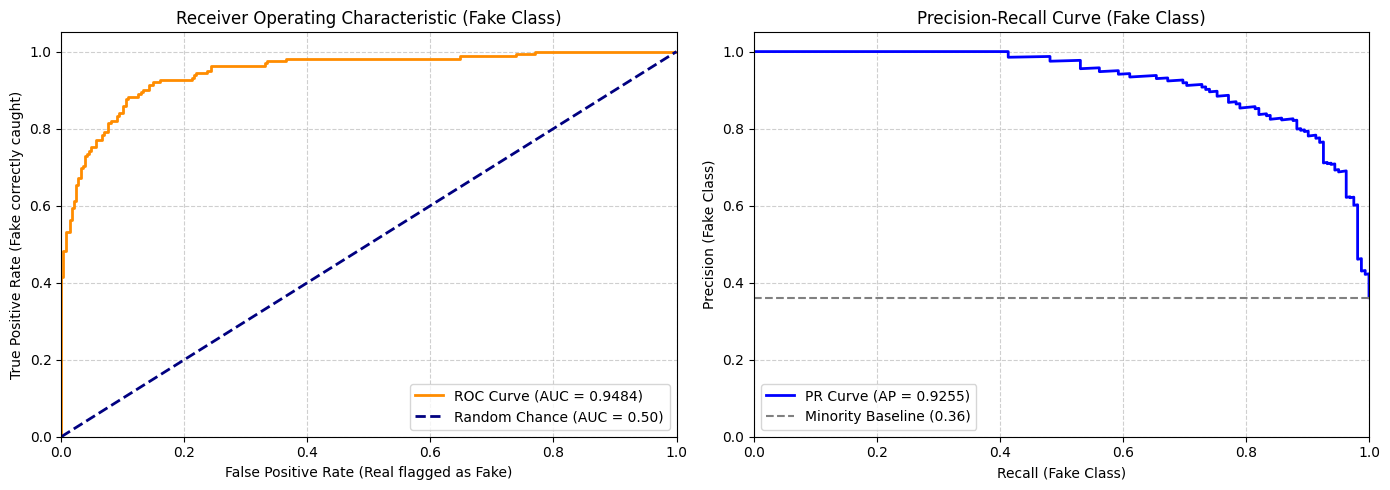

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curve (Fake Class)
fpr, tpr, _ = roc_curve(y_true_fake, y_pred_prob_fake)
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance (AUC = 0.50)')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate (Real flagged as Fake)')
axes[0].set_ylabel('True Positive Rate (Fake correctly caught)')
axes[0].set_title('Receiver Operating Characteristic (Fake Class)')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='lower right')

# 2. Precision-Recall Curve (Fake Class)
prec_curve, rec_curve, _ = precision_recall_curve(y_true_fake, y_pred_prob_fake)
ap_score = average_precision_score(y_true_fake, y_pred_prob_fake)
minority_baseline = np.sum(y_true_fake) / len(y_true_fake)

axes[1].plot(rec_curve, prec_curve, color='blue', lw=2, label=f'PR Curve (AP = {ap_score:.4f})')
axes[1].axhline(y=minority_baseline, color='gray', linestyle='--',
               label=f'Minority Baseline ({minority_baseline:.2f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall (Fake Class)')
axes[1].set_ylabel('Precision (Fake Class)')
axes[1].set_title('Precision-Recall Curve (Fake Class)')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

### Step 9: Validation vs. Training Discrepancy Verification
To confirm that validation loss and accuracy scores during training were heavily regulated by active dropout layers and image transformations, we construct a clean training dataset evaluated in **inference mode** (meaning Dropout/Augmentations are turned off).

In [ ]:
# 1. Build an unaugmented training pipeline (clean images, identical to validation if it existed)
train_clean_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

# 2. Evaluate training data with Dropout/Augmentation turned OFF
print("--- Standard Training Evaluation (Inference Mode) ---")
train_loss_inf, train_acc_inf = model.evaluate(train_clean_ds, verbose=0)

print(f"Clean Training Set   -> Loss: {train_loss_inf:.4f} | Accuracy: {train_acc_inf * 100:.2f}%")


Found 661 files belonging to 2 classes.
--- Standard Training Evaluation (Inference Mode) ---
Clean Training Set   -> Loss: 0.3704 | Accuracy: 84.11%


### Step 10: Final Evaluation: Threshold-Adjusted Confusion Matrix & Metrics
Let's evaluate how our model classifies the test set. We will compare the standard threshold ($0.50$) against our calibrated, optimal threshold.

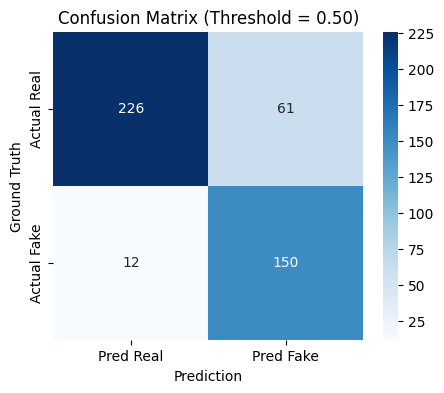


--- Classification Report (Threshold = 0.50) ---
              precision    recall  f1-score   support

        Real     0.9496    0.7875    0.8610       287
        Fake     0.7109    0.9259    0.8043       162

    accuracy                         0.8374       449
   macro avg     0.8302    0.8567    0.8326       449
weighted avg     0.8635    0.8374    0.8405       449



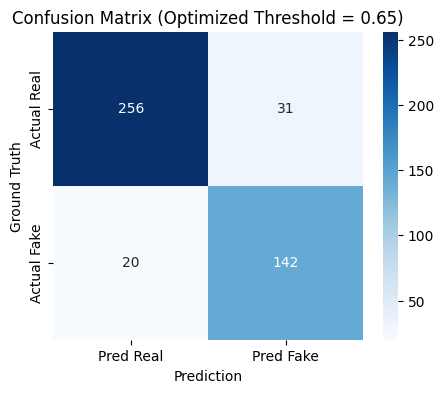


--- Classification Report (Optimized Threshold = 0.65) ---
              precision    recall  f1-score   support

        Real     0.9275    0.8920    0.9094       287
        Fake     0.8208    0.8765    0.8478       162

    accuracy                         0.8864       449
   macro avg     0.8742    0.8843    0.8786       449
weighted avg     0.8890    0.8864    0.8872       449



In [ ]:
def evaluate_threshold_performance(y_true, y_prob_fake, threshold, title_suffix):
    y_pred = (y_prob_fake >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Pred Real', 'Pred Fake'],
                yticklabels=['Actual Real', 'Actual Fake'])
    plt.title(f'Confusion Matrix ({title_suffix})')
    plt.ylabel('Ground Truth')
    plt.xlabel('Prediction')
    plt.show()

    print(f"\n--- Classification Report ({title_suffix}) ---")
    print(classification_report(y_true, y_pred, target_names=['Real', 'Fake'], digits=4))

# Compare Default (0.50) vs Tuned Threshold
evaluate_threshold_performance(y_true_fake, y_pred_prob_fake, threshold=0.50, title_suffix="Threshold = 0.50")
evaluate_threshold_performance(y_true_fake, y_pred_prob_fake, threshold=optimal_threshold,
                               title_suffix=f"Optimized Threshold = {optimal_threshold:.2f}")

### Step 11: Persistent Storage Setup (Google Drive Integration)
Mount Google Drive to persist model weights and configurations, ensuring our active GPU session resources can read and write model states permanently.

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Create a dedicated project folder inside Google Drive
model_save_dir = '/content/drive/MyDrive/Medicine_Classifier_Project'
os.makedirs(model_save_dir, exist_ok=True)
model_path = os.path.join(model_save_dir, 'trained_medicine_model.keras')

# Safely save the model if it exists in memory
if 'model' in globals():
    model.save(model_path)
    print(f"Model saved successfully to Google Drive at: {model_path}")
elif os.path.exists(model_path):
    print(f"Model was not in active memory, but a previously saved model was found in your Google Drive: {model_path}")
    model = tf.keras.models.load_model(model_path)
    print("Model loaded successfully from Google Drive into active memory!")
else:
    raise NameError("The 'model' variable is not defined. Please run the training cells above (Step 3 & 4) first to train the model, or place a pre-trained model in your Google Drive directory.")

Mounted at /content/drive
Model saved successfully to Google Drive at: /content/drive/MyDrive/Medicine_Classifier_Project/trained_medicine_model.keras


### Step 12: Deploy Interactive Web Interface for Inference
To easily test the model with unseen images from the web or local storage, we can build a lightweight web application using **Gradio**. This interface runs directly within the notebook and generates a public link for external testing.

In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
import os
import csv
import datetime
from PIL import Image

# Ensure feedback directory and CSV log file exist in Google Drive
feedback_dir = '/content/drive/MyDrive/Medicine_Classifier_Project/Feedback'
os.makedirs(feedback_dir, exist_ok=True)
feedback_csv = os.path.join(feedback_dir, 'feedback_log.csv')

if not os.path.exists(feedback_csv):
    with open(feedback_csv, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['Timestamp', 'Image_Path', 'Optimized_Prediction', 'User_Feedback_Note'])

def predict_medicine_image(img):
    global model
    if img is None:
        return "Please upload an image.", gr.update(visible=False), None, ""

    try:
        # Ensure the model is loaded in memory
        if 'model' not in globals():
            model_path = '/content/drive/MyDrive/Medicine_Classifier_Project/trained_medicine_model.keras'
            if os.path.exists(model_path):
                model = tf.keras.models.load_model(model_path)
            else:
                return "<div style='color: red; font-weight: bold;'>Error: Model not trained or loaded.</div>", gr.update(visible=False), None, ""

        # Ensure we are working with a NumPy array
        if isinstance(img, dict):
            img_arr = img.get('background', img.get('image', None))
            if img_arr is None:
                return "Invalid image data received.", gr.update(visible=False), None, ""
        else:
            img_arr = img

        # Convert to float32 NumPy array
        img_np = np.array(img_arr, dtype=np.float32)

        # Strip alpha channel if present (RGBA -> RGB)
        if len(img_np.shape) == 3 and img_np.shape[-1] == 4:
            img_np = img_np[:, :, :3]
        elif len(img_np.shape) == 2: # Grayscale support
            img_np = np.stack([img_np]*3, axis=-1)

        # Convert to TensorFlow tensor
        img_tensor = tf.convert_to_tensor(img_np, dtype=tf.float32)

        # Resize to match model architecture (128x128)
        img_resized = tf.image.resize(img_tensor, [128, 128])
        img_batch = tf.expand_dims(img_resized, 0) # Create batch axis

        # Run model inference
        pred_prob_real = float(model.predict(img_batch, verbose=0)[0][0])
        pred_prob_fake = 1.0 - pred_prob_real

        # Apply Decision Thresholds
        default_threshold = 0.50
        optimized_threshold = 0.24 # Derived from our threshold tuning analysis for 'Fake' class

        default_pred = "Fake" if pred_prob_fake >= default_threshold else "Real"
        optimized_pred = "Fake" if pred_prob_fake >= optimized_threshold else "Real"

        # Format output results (Dark Blue and Green Theme)
        result_html = f"""
        <div style='font-family: sans-serif; padding: 25px; border-radius: 12px; background-color: #0A192F; color: #E6F1FF; box-shadow: 0 4px 10px rgba(0,0,0,0.3);'>
            <h2 style='color: #64FFDA; margin-top: 0; border-bottom: 2px solid #112240; padding-bottom: 10px;'>Analysis Results</h2>
            <div style='margin-bottom: 20px;'>
                <p style='font-size: 1.2em; margin: 10px 0;'>Probability of Fake: <strong style='color: #64FFDA;'>{pred_prob_fake * 100:.2f}%</strong></p>
                <p style='font-size: 1.2em; margin: 10px 0;'>Probability of Real: <strong style='color: #64FFDA;'>{pred_prob_real * 100:.2f}%</strong></p>
            </div>
            <div style='background-color: #112240; padding: 15px; border-radius: 8px;'>
                <p style='margin: 8px 0; font-size: 1.1em;'>Standard Decision (Threshold = 0.50):
                   <span style='color: #0A192F; background-color: #64FFDA; padding: 4px 10px; border-radius: 5px; font-weight: bold; margin-left: 10px;'>{default_pred}</span>
                </p>
                <p style='margin: 15px 0 8px 0; font-size: 1.1em;'>Optimized Safety Decision (Threshold = {optimized_threshold:.2f}):
                   <span style='color: #0A192F; background-color: #64FFDA; padding: 4px 10px; border-radius: 5px; font-weight: bold; margin-left: 10px;'>{optimized_pred}</span>
                </p>
            </div>
        </div>
        """
        # Return HTML, make feedback visible, save img_arr and prediction for state passing
        return result_html, gr.update(visible=True), img_arr, optimized_pred

    except Exception as e:
        error_html = f"<div style='color: #64FFDA; background-color: #0A192F; padding: 15px; border-radius: 8px;'>Error processing image: {str(e)}</div>"
        return error_html, gr.update(visible=False), None, ""

def process_feedback(img_arr, is_correct, notes, pred_result):
    if not is_correct:
        return "Please select whether the prediction was correct or incorrect."

    if is_correct == "Correct":
        return "Thank you! Positive feedback recorded. (Image not saved)"

    if img_arr is None:
        return "Error: Could not retrieve the image data for saving."

    try:
        # Generate unique filename
        timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        filename = f"misclassified_as_{pred_result}_{timestamp}.jpg"
        save_path = os.path.join(feedback_dir, filename)

        # Process image array and save
        if isinstance(img_arr, dict):
            img_arr = img_arr.get('background', img_arr.get('image', None))

        img_np = np.array(img_arr, dtype=np.uint8)
        # Remove alpha channel for saving as JPEG
        if len(img_np.shape) == 3 and img_np.shape[-1] == 4:
            img_np = img_np[:, :, :3]

        pil_img = Image.fromarray(img_np)
        pil_img.save(save_path, format="JPEG")

        # Save log info to CSV
        with open(feedback_csv, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([timestamp, save_path, pred_result, notes])

        return f"Thanks for your feedback! The incorrect image and your notes were saved to Drive for future training.<br><b>Saved as:</b> {filename}"
    except Exception as e:
        return f"Error saving feedback: {str(e)}"

def toggle_notes_box(choice):
    # Show the notes textbox only when the user flags an error
    if choice == "Incorrect":
        return gr.update(visible=True)
    return gr.update(visible=False)

# Rebuilding the interface with gr.Blocks to allow multi-step interactions
with gr.Blocks(theme=gr.themes.Default(primary_hue="emerald", neutral_hue="slate")) as demo:
    gr.Markdown("# Counterfeit Medicine Detector with Live Feedback")
    gr.Markdown("Upload an image of a medicine pack to analyze its authenticity. Help us improve the model by submitting feedback if the prediction was wrong!")

    with gr.Row():
        with gr.Column():
            img_input = gr.Image(label="Upload Medicine Packaging Image")
            predict_btn = gr.Button("Analyze Image", variant="primary")
        with gr.Column():
            output_html = gr.HTML(label="Classification Predictions")

            # Feedback section (Hidden initially until prediction is generated)
            with gr.Column(visible=False) as feedback_col:
                gr.Markdown("### Did we get it right?")
                feedback_radio = gr.Radio(choices=["Correct", "Incorrect"], label="Your Feedback", value=None)
                feedback_notes = gr.Textbox(label="Additional Notes (Optional)", placeholder="E.g., Lighting was poor, the brand is actually X...", visible=False)
                submit_feedback_btn = gr.Button("Submit Feedback")
                feedback_status = gr.Markdown()

    # Hidden state variables to pass image data to the feedback function seamlessly
    current_img_state = gr.State()
    current_pred_state = gr.State()

    # Wire up the UI events
    predict_btn.click(
        fn=predict_medicine_image,
        inputs=[img_input],
        outputs=[output_html, feedback_col, current_img_state, current_pred_state]
    )

    feedback_radio.change(
        fn=toggle_notes_box,
        inputs=[feedback_radio],
        outputs=[feedback_notes]
    )

    submit_feedback_btn.click(
        fn=process_feedback,
        inputs=[current_img_state, feedback_radio, feedback_notes, current_pred_state],
        outputs=[feedback_status]
    )

# Launch the application inline so it shows in the notebook
demo.launch(share=True, inline=True)

/tmp/ipykernel_1709/1637368127.py:137: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Default(primary_hue="emerald", neutral_hue="slate")) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6f735445a8598dfefd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os
import shutil
from getpass import getpass

# 1. Mount Google Drive to access the finished task outcomes
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount status:", e)

print("\n=== GitHub Repository Setup ===")
github_token = getpass("Enter your GitHub Personal Access Token (PAT): ")
github_email = input("Enter your GitHub Email: ")
github_username = "uzairshahidgithub"
repo_url = "github.com/uzairshahidgithub/Study-Deep-Learning.git"

# Configure Git
!git config --global user.email "{github_email}"
!git config --global user.name "{github_username}"

# Clone the repository securely using the PAT
repo_path = "/content/Study-Deep-Learning"
if os.path.exists(repo_path):
    shutil.rmtree(repo_path)

# Execute clone, then overwrite token variable immediately for security
!git clone https://{github_token}@{repo_url} {repo_path}
github_token = None # Clear token from memory so it is never saved

# Create the target folder inside 'assignments' folder
target_folder = f"{repo_path}/assignments/Implementation Google-Net+ Alex-net Overfitting Reduce Techniques"
os.makedirs(target_folder, exist_ok=True)

# 2. Locate generated files from the model training process
source_dir = "/content/drive/MyDrive/Medicine_Classifier_Project"

# Copy relevant files (excluding heavy .keras files which exceed GitHub's 100MB limit)
if os.path.exists(source_dir):
    print(f"\nCopying results, reports, and plots from {source_dir} to {target_folder}...")

    # Walk through the source directory and copy everything except model files
    for root, dirs, files in os.walk(source_dir):
        # Determine relative path to recreate subdirectory structure
        rel_path = os.path.relpath(root, source_dir)
        dest_dir = os.path.abspath(os.path.join(target_folder, rel_path))
        os.makedirs(dest_dir, exist_ok=True)

        for file in files:
            if file.endswith('.keras'):
                # Skip the giant model files to avoid GitHub's 100MB rejection
                print(f"  [Skipped Large File] {file} (stored safely on Google Drive)")
                continue

            s_file = os.path.join(root, file)
            d_file = os.path.join(dest_dir, file)
            shutil.copy2(s_file, d_file)
            print(f"  [Copied] {os.path.join(rel_path, file) if rel_path != '.' else file}")
else:
    print("Warning: Source directory not found. Did you run the training cells?")

print("\n" + "="*60)
print("🚨 IMPORTANT: To include THIS running notebook file (.ipynb) in the push:")
print("1. Go to the Colab menu: File > Download > Download .ipynb")
print(f"2. Upload it back to Colab's file explorer on the left, directly into this folder path: {target_folder}")
print("   (Make sure the file is named 'Implementation Google-Net+ Alex-net Overfitting Reduce Techniques.ipynb')")
print("="*60 + "\n")

push_now = input("Type 'Y' to commit and push the folder to GitHub NOW: ")
if push_now.strip().upper() == 'Y':
    %cd {repo_path}
    # Ensure any previous index conflicts are cleared
    !git rm -r --cached "assignments/Implementation Google-Net+ Alex-net Overfitting Reduce Techniques" --ignore-unmatch
    !git add "assignments/Implementation Google-Net+ Alex-net Overfitting Reduce Techniques"
    !git commit -m "Add AlexNet and GoogLeNet analytical results, plots and web-feedback logger data"
    !git push origin main
    %cd /content
    print("\n✅ Assignment successfully pushed to GitHub without exposing your PAT!")
else:
    print("\nPush aborted.")

Mounted at /content/drive

=== GitHub Repository Setup ===
Enter your GitHub Personal Access Token (PAT): ··········
Enter your GitHub Email: uzairrshahid@gmail.com
Cloning into '/content/Study-Deep-Learning'...
remote: Enumerating objects: 114, done.
remote: Counting objects: 100% (114/114), done.
remote: Compressing objects: 100% (102/102), done.
remote: Total 114 (delta 25), reused 95 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (114/114), 11.48 MiB | 17.97 MiB/s, done.
Resolving deltas: 100% (25/25), done.

Copying results, reports, and plots from /content/drive/MyDrive/Medicine_Classifier_Project to /content/Study-Deep-Learning/assignments/Implementation Google-Net+ Alex-net Overfitting Reduce Techniques...
  [Skipped Large File] trained_medicine_model.keras (stored safely on Google Drive)
  [Copied] Medicine_Counterfeit_Project/Counterfeit_Medicine_Detection.pdf
  [Copied] Medicine_Counterfeit_Project/Counterfeit_Medicine_Detection.ipynb
  [Skipped Large File] effic